In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('data/superstore_muestra.csv')
df

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Technology,Papakura,New Zealand,KL-166451,Ken Lonsdale,0.40,APAC,1,2011-01-03,ID-2011-80230,...,69,Consumer,2011-01-09 00:00:00.000,Standard Class,8.340,Auckland,Accessories,2011,APAC,2
1,Office Supplies,Yazd,Iran,JO-52801,Jas O'Carroll,0.00,EMEA,1,2011-01-03,IR-2011-770,...,123,Consumer,2011-01-07 00:00:00.000,Standard Class,8.410,Yazd,Appliances,2011,EMEA,2
2,Office Supplies,Francisco Beltrão,Brazil,RA-199153,Russell Applegate,0.00,LATAM,1,2011-01-04,MX-2011-111255,...,149,Consumer,2011-01-09 00:00:00.000,Second Class,10.383,Parana,Supplies,2011,LATAM,2
3,Office Supplies,Houston,United States,DP-130004,Darren Powers,0.20,US,1,2011-01-04,CA-2011-103800,...,16,Consumer,2011-01-08 00:00:00.000,Standard Class,1.820,Texas,Paper,2011,North America,2
4,Office Supplies,Philadelphia,United States,MB-180854,Mick Brown,0.20,US,1,2011-01-06,CA-2011-141817,...,20,Consumer,2011-01-13 00:00:00.000,Standard Class,1.850,Pennsylvania,Art,2011,North America,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5125,Furniture,Jakarta,Indonesia,ML-173951,Marina Lichtenstein,0.07,APAC,1,2014-12-31,IN-2014-43550,...,1091,Corporate,2015-01-01 00:00:00.000,First Class,243.110,Jakarta,Bookcases,2014,APAC,53
5126,Technology,Eindhoven,Netherlands,JK-156402,Jim Kriz,0.50,EU,1,2014-12-31,IT-2014-3715679,...,108,Home Office,2015-01-05 00:00:00.000,Second Class,22.090,North Brabant,Machines,2014,EU,53
5127,Office Supplies,Eindhoven,Netherlands,JK-156402,Jim Kriz,0.50,EU,1,2014-12-31,IT-2014-3715679,...,23,Home Office,2015-01-05 00:00:00.000,Second Class,3.460,North Brabant,Binders,2014,EU,53
5128,Technology,New York City,United States,PO-188654,Patrick O'Donnell,0.00,US,1,2014-12-31,CA-2014-143259,...,91,Consumer,2015-01-04 00:00:00.000,Standard Class,9.670,New York,Phones,2014,North America,53


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5130 entries, 0 to 5129
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        5130 non-null   str    
 1   City            5130 non-null   str    
 2   Country         5130 non-null   str    
 3   Customer.ID     5130 non-null   str    
 4   Customer.Name   5130 non-null   str    
 5   Discount        5130 non-null   float64
 6   Market          5130 non-null   str    
 7   记录数             5130 non-null   int64  
 8   Order.Date      5130 non-null   str    
 9   Order.ID        5130 non-null   str    
 10  Order.Priority  5130 non-null   str    
 11  Product.ID      5130 non-null   str    
 12  Product.Name    5130 non-null   str    
 13  Profit          5130 non-null   float64
 14  Quantity        5130 non-null   int64  
 15  Region          5130 non-null   str    
 16  Row.ID          5130 non-null   int64  
 17  Sales           5130 non-null   int64  
 18 

In [4]:
df.head(10)

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Technology,Papakura,New Zealand,KL-166451,Ken Lonsdale,0.4,APAC,1,2011-01-03,ID-2011-80230,...,69,Consumer,2011-01-09 00:00:00.000,Standard Class,8.340,Auckland,Accessories,2011,APAC,2
1,Office Supplies,Yazd,Iran,JO-52801,Jas O'Carroll,0.0,EMEA,1,2011-01-03,IR-2011-770,...,123,Consumer,2011-01-07 00:00:00.000,Standard Class,8.410,Yazd,Appliances,2011,EMEA,2
2,Office Supplies,Francisco Beltrão,Brazil,RA-199153,Russell Applegate,0.0,LATAM,1,2011-01-04,MX-2011-111255,...,149,Consumer,2011-01-09 00:00:00.000,Second Class,10.383,Parana,Supplies,2011,LATAM,2
3,Office Supplies,Houston,United States,DP-130004,Darren Powers,0.2,US,1,2011-01-04,CA-2011-103800,...,16,Consumer,2011-01-08 00:00:00.000,Standard Class,1.820,Texas,Paper,2011,North America,2
4,Office Supplies,Philadelphia,United States,MB-180854,Mick Brown,0.2,US,1,2011-01-06,CA-2011-141817,...,20,Consumer,2011-01-13 00:00:00.000,Standard Class,1.850,Pennsylvania,Art,2011,North America,2
5,Office Supplies,Henderson,United States,ME-173204,Maria Etezadi,0.0,US,1,2011-01-07,CA-2011-167199,...,610,Home Office,2011-01-11 00:00:00.000,Standard Class,88.070,Kentucky,Binders,2011,North America,2
6,Technology,Beirut,Lebanon,HM-48602,Harry Marie,0.0,EMEA,1,2011-01-07,LE-2011-9590,...,174,Corporate,2011-01-11 00:00:00.000,Standard Class,23.840,Beirut,Copiers,2011,EMEA,2
7,Office Supplies,Nanning,China,PO-188651,Patrick O'Donnell,0.0,APAC,1,2011-01-10,IN-2011-13065,...,34,Consumer,2011-01-11 00:00:00.000,First Class,5.260,Guangxi,Binders,2011,APAC,3
8,Furniture,San Pablo de las Salinas,Mexico,PF-191653,Philip Fox,0.2,LATAM,1,2011-01-11,US-2011-163874,...,452,Consumer,2011-01-12 00:00:00.000,First Class,57.746,México,Bookcases,2011,LATAM,3
9,Office Supplies,Lagos,Nigeria,SC-104401,Shaun Chance,0.7,Africa,1,2011-01-12,NI-2011-1670,...,5,Corporate,2011-01-16 00:00:00.000,Standard Class,0.430,Lagos,Supplies,2011,Africa,3


In [5]:
df.tail(10)

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
5120,Furniture,Ho Chi Minh City,Vietnam,JW-160751,Julia West,0.37,APAC,1,2014-12-30,ID-2014-52902,...,272,Consumer,2015-01-01 00:00:00.000,First Class,68.070,Ho Chí Minh City,Bookcases,2014,APAC,53
5121,Technology,Ho Chi Minh City,Vietnam,JW-160751,Julia West,0.47,APAC,1,2014-12-30,ID-2014-52902,...,327,Consumer,2015-01-01 00:00:00.000,First Class,44.800,Ho Chí Minh City,Accessories,2014,APAC,53
5122,Furniture,Canberra,Australia,NP-183251,Naresj Patel,0.40,APAC,1,2014-12-30,ID-2014-51509,...,434,Consumer,2015-01-01 00:00:00.000,Second Class,124.630,Australian Capital Territory,Chairs,2014,APAC,53
5123,Furniture,Anaheim,United States,BP-111854,Ben Peterman,0.00,US,1,2014-12-30,CA-2014-146626,...,101,Corporate,2015-01-06 00:00:00.000,Standard Class,11.070,California,Furnishings,2014,North America,53
5124,Office Supplies,Managua,Nicaragua,RB-194653,Rick Bensley,0.00,LATAM,1,2014-12-31,MX-2014-141712,...,120,Home Office,2014-12-31 00:00:00.000,Same Day,43.347,Managua,Paper,2014,LATAM,53
5125,Furniture,Jakarta,Indonesia,ML-173951,Marina Lichtenstein,0.07,APAC,1,2014-12-31,IN-2014-43550,...,1091,Corporate,2015-01-01 00:00:00.000,First Class,243.110,Jakarta,Bookcases,2014,APAC,53
5126,Technology,Eindhoven,Netherlands,JK-156402,Jim Kriz,0.50,EU,1,2014-12-31,IT-2014-3715679,...,108,Home Office,2015-01-05 00:00:00.000,Second Class,22.090,North Brabant,Machines,2014,EU,53
5127,Office Supplies,Eindhoven,Netherlands,JK-156402,Jim Kriz,0.50,EU,1,2014-12-31,IT-2014-3715679,...,23,Home Office,2015-01-05 00:00:00.000,Second Class,3.460,North Brabant,Binders,2014,EU,53
5128,Technology,New York City,United States,PO-188654,Patrick O'Donnell,0.00,US,1,2014-12-31,CA-2014-143259,...,91,Consumer,2015-01-04 00:00:00.000,Standard Class,9.670,New York,Phones,2014,North America,53
5129,Technology,Juba,South Sudan,MW-82351,Mitch Willingham,0.00,Africa,1,2014-12-31,OD-2014-9490,...,378,Corporate,2015-01-05 00:00:00.000,Standard Class,11.710,Central Equatoria,Copiers,2014,Africa,53


In [6]:
df.describe()

,Discount,记录数,Profit,Quantity,Row.ID,Sales,Shipping.Cost,Year,weeknum
count,5130.000000,5130.0,5130.000000,5130.000000,5130.000000,5130.000000,5130.000000,5130.000000,5130.000000
mean,0.141182,1.0,27.884175,3.498246,25524.069786,245.246784,26.030335,2012.777583,31.278558
std,0.209825,0.0,164.995050,2.301528,14731.305219,454.334173,53.933320,1.099214,14.437182
min,0.000000,1.0,-3839.990400,1.000000,2.000000,1.000000,0.003000,2011.000000,1.000000
25%,0.000000,1.0,0.000000,2.000000,12538.000000,31.000000,2.700000,2012.000000,20.000000
50%,0.000000,1.0,9.205000,3.000000,25617.500000,86.000000,8.046500,2013.000000,33.000000
75%,0.200000,1.0,38.272500,5.000000,38121.750000,255.000000,24.200000,2014.000000,44.000000
max,0.850000,1.0,3979.080000,14.000000,51274.000000,8000.000000,801.660000,2014.000000,53.000000


In [7]:
df.describe(include="O")

,Category,City,Country,Customer.ID,Customer.Name,Market,Order.Date,Order.ID,Order.Priority,Product.ID,Product.Name,Region,Segment,Ship.Date,Ship.Mode,State,Sub.Category,Market2
count,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130,5130
unique,3,1754,125,2902,790,7,1252,4651,4,3882,2382,13,3,1345,4,725,17,6
top,Office Supplies,New York City,United States,BC-111252,Karl Braun,APAC,2014-06-18,NI-2014-8880,Medium,OFF-STA-10001895,Staples,Central,Consumer,2014-11-16 00:00:00.000,Standard Class,California,Binders,APAC
freq,3105,88,1004,10,16,1107,17,5,2944,6,22,1130,2673,14,3125,213,604,1107


In [8]:
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', '记录数', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isna().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

In [11]:
df['记录数'].value_counts()


记录数
1    5130
Name: count, dtype: int64

In [12]:
df.drop(columns=['记录数'], inplace=True)

In [13]:
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')

In [14]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"numerical_cols are:\n {numerical_cols}")
print('\n')
print(f"categorical_cols are: \n {categorical_cols}")

numerical_cols are:
 ['Discount', 'Profit', 'Quantity', 'Row.ID', 'Sales', 'Shipping.Cost', 'Year', 'weeknum']


categorical_cols are: 
 ['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name', 'Market', 'Order.Date', 'Order.ID', 'Order.Priority', 'Product.ID', 'Product.Name', 'Region', 'Segment', 'Ship.Date', 'Ship.Mode', 'State', 'Sub.Category', 'Market2']


In [15]:
df['Order.Date'] = pd.to_datetime(df['Order.Date'])
df['Ship.Date'] = pd.to_datetime(df['Ship.Date'])

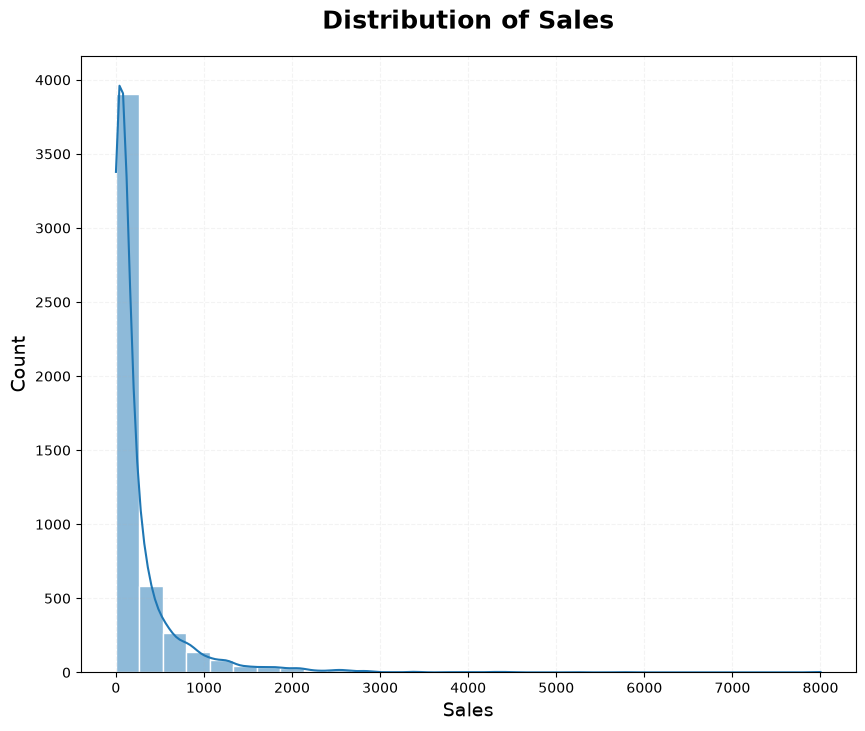

In [16]:
plt.figure(figsize=(10, 8))
sns.histplot(data=df, x='Sales', bins=30, kde=True,

             color='#1f77b4', edgecolor='white')
plt.title('Distribution of Sales', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Sales', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.grid(True, alpha=0.15, linestyle='--')
plt.show()

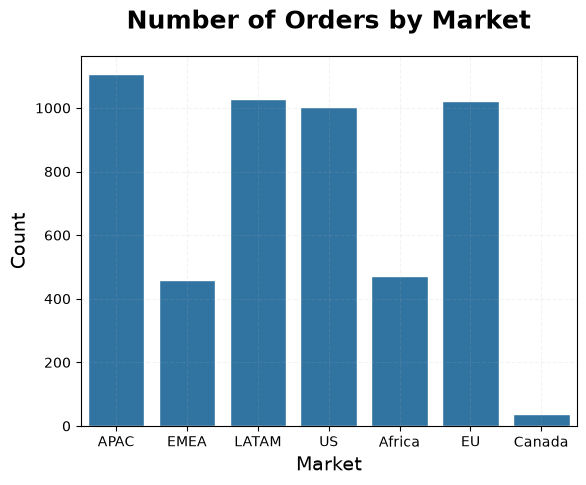

In [17]:
sns.countplot(data=df, x='Market',color='#1f77b4', edgecolor='white')
plt.title('Number of Orders by Market', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Market', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.grid(True, alpha=0.15, linestyle='--')
plt.show()

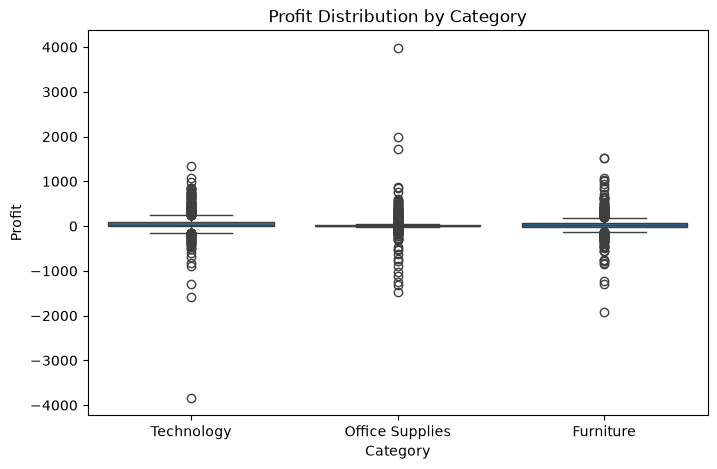

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Category', y='Profit',color='#1f77b4')
plt.title('Profit Distribution by Category')
plt.xlabel('Category')
plt.ylabel('Profit')
plt.show()

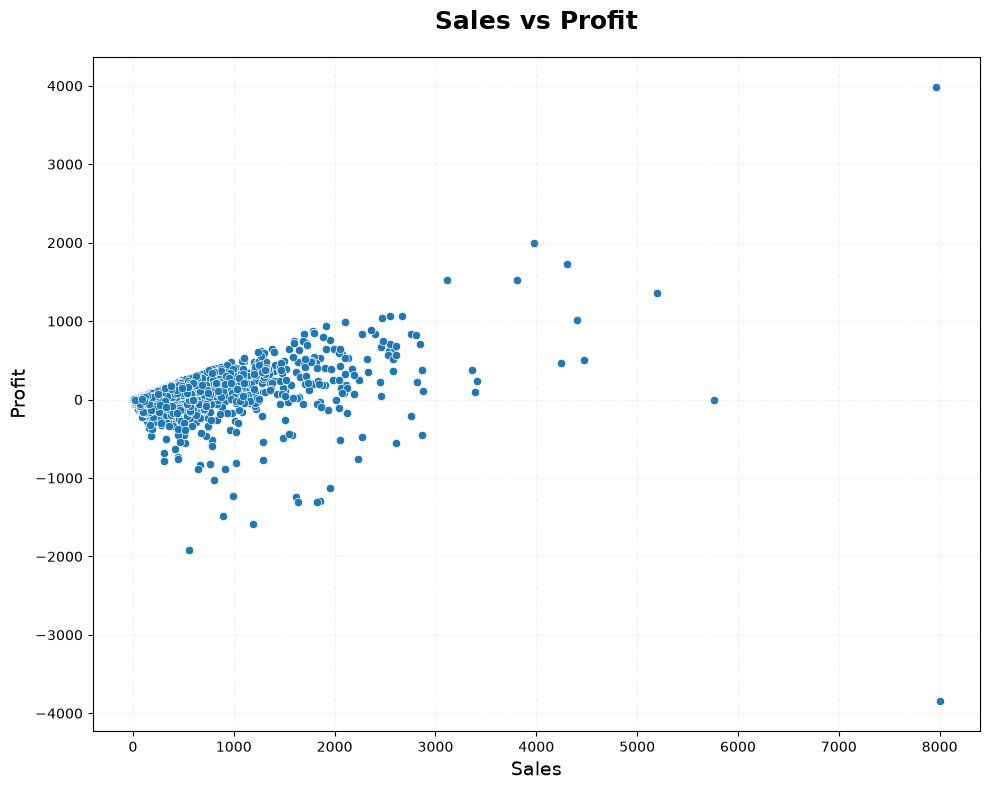

In [19]:
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df, x='Sales', y='Profit', palette='coolwarm',)
plt.title('Sales vs Profit', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Sales', fontsize=14)
plt.ylabel('Profit', fontsize=14)
plt.grid(True, alpha=0.15, linestyle='--')
plt.tight_layout()
plt.show()

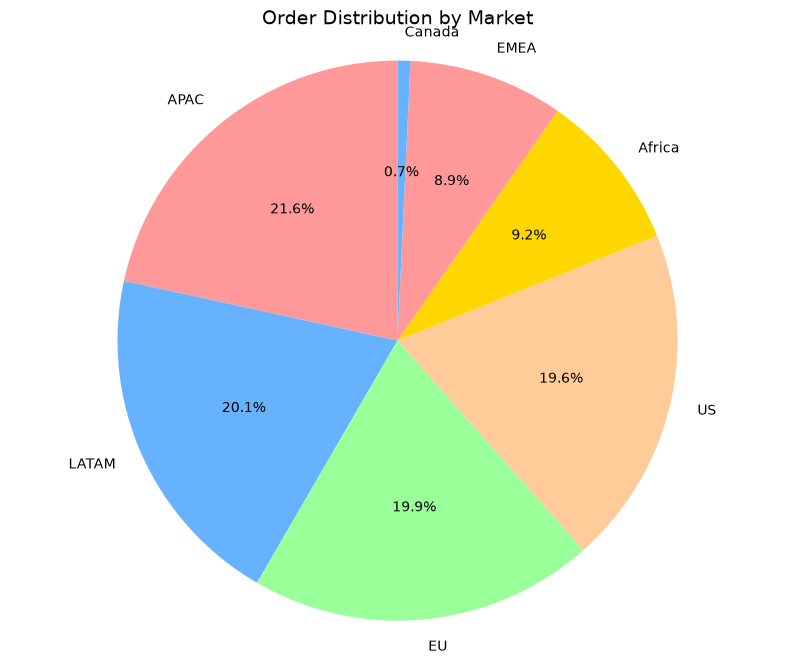

In [20]:
plt.figure(figsize=(10, 8))
market_counts = df['Market'].value_counts()
plt.pie(market_counts.values, labels=market_counts.index, autopct='%1.1f%%',
        startangle=90, colors=['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#FFD700'])
plt.title('Order Distribution by Market', fontsize=14)
plt.axis('equal') 
plt.show()

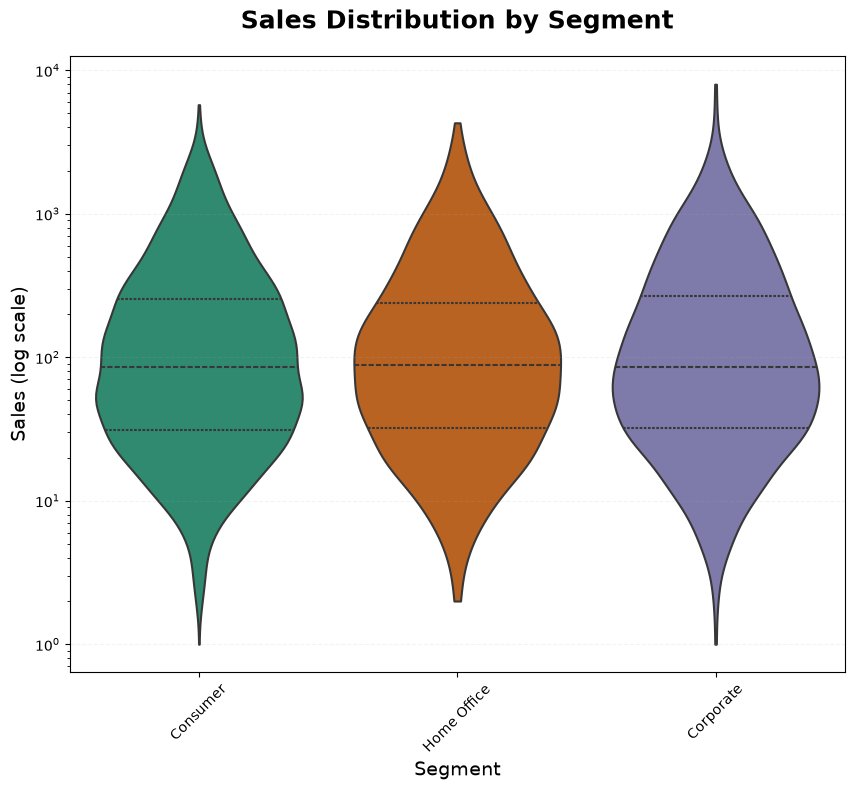

In [21]:
plt.figure(figsize=(10, 8))
sns.violinplot(data=df, x='Segment', y='Sales',
               palette=['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e'],
               inner='quartile', linewidth=1.5, saturation=0.7, cut=0, log_scale=True)
plt.title('Sales Distribution by Segment', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Segment', fontsize=14)
plt.ylabel('Sales (log scale)', fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.15, axis='y', linestyle='--')
plt.show()

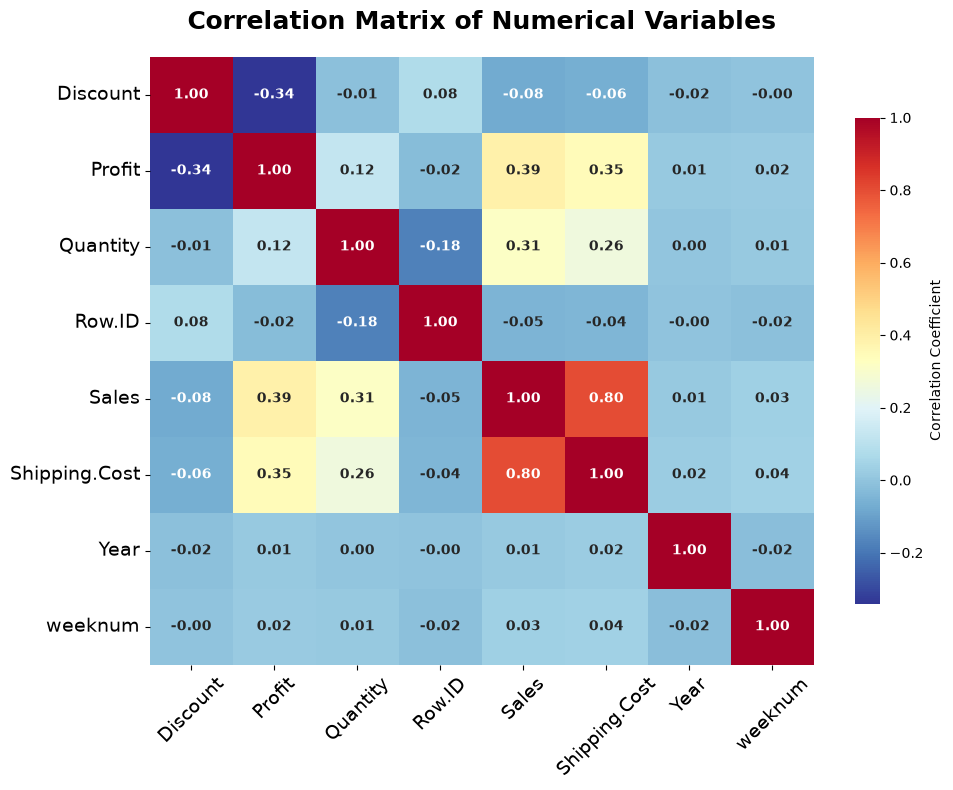

In [22]:
plt.figure(figsize=(10, 8))
corr_matrix = df[numerical_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='RdYlBu_r',
            cbar_kws={'label': 'Correlation Coefficient', 'shrink': 0.8},
            annot_kws={'size': 10, 'weight': 'bold'})

plt.title('Correlation Matrix of Numerical Variables', fontsize=18, fontweight='bold', pad=20)
plt.xticks(rotation=45, fontsize=14)
plt.yticks(rotation=0, fontsize=14)
plt.tight_layout()
plt.show()

In [23]:
import os
downloads_path = os.path.join(os.path.expanduser("~"), "Downloads", "Global_Superstore_muestra.xlsx")
df.to_excel('Global_Superstore_muestra.xlsx', sheet_name='Sheet1', index=False)

In [24]:
import os
if os.path.exists('Global_Superstore_muestra.xlsx'):
    print("File saved successfully!")
else:
    print("File not found. Check the file path and permissions.")

File saved successfully!
